# 08 · Pathway, transcription-factor and Hallmark activity

Lists of hundreds of DEGs are hard to interpret. Footprint-based enrichment
summarises them into the activity of signalling pathways and transcription
factors (TFs), using the **signed edgeR statistic of every tested gene**
(no arbitrary DEG cut-off):

| resource | sources | idea |
|---|---|---|
| PROGENy | 14 pathways | genes that *respond* to pathway perturbation (500 per pathway) |
| CollecTRI | ~1,100 TFs | signed TF → target regulons |
| MSigDB Hallmark | 50 programmes | well-defined biological states |

Scores come from a univariate linear model (decoupler ULM): activity = t-value
of the slope of gene statistics on source weights; P values are BH-adjusted
across sources per cell type.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import seaborn as sns

from ipfatlas import enrichment, pseudobulk
from ipfatlas.config import setup
from ipfatlas.plotting import embedding_scatter, figsize, panel_label, save_figure, set_style
from ipfatlas.utils import write_table

cfg, P = setup()
set_style(cfg["figures"]["font_size"])
FIG = P.figures / "08_pathways"
TAB = P.tables / "08_pathways"

edger = pd.read_csv(P.tables / "07_de" / "edgeR_IPF_vs_control_all_celltypes.csv.gz")
stat = pseudobulk.stat_matrix(edger, "stat")
print(stat.shape)

(31, 14349)


## 1. Resources

In [2]:
progeny = enrichment.resource("progeny", top=500)
collectri = enrichment.resource("collectri")
hallmark = enrichment.resource("hallmark")
hallmark["source"] = hallmark["source"].str.replace("_", " ")
print(progeny.source.nunique(), "PROGENy pathways |", collectri.source.nunique(), "TFs |",
      hallmark.source.nunique(), "Hallmarks")


def heatmap(scores, padj, title, name, vmax=None, figsize_mm=(183, 90), cluster=True):
    s = scores.copy()
    vmax = vmax or np.nanpercentile(np.abs(s.values), 98)
    annot = np.where(padj.reindex_like(s).values < 0.05, "•", "")
    if cluster and min(s.shape) > 2:
        g = sns.clustermap(s, cmap="RdBu_r", center=0, vmin=-vmax, vmax=vmax, annot=annot, fmt="",
                           annot_kws={"fontsize": 5}, figsize=(figsize_mm[0] / 25.4, figsize_mm[1] / 25.4),
                           xticklabels=True, yticklabels=True, cbar_kws={"label": "activity (t)"},
                           dendrogram_ratio=0.06, linewidths=0)
        g.ax_heatmap.tick_params(labelsize=5)
        g.ax_heatmap.set_xlabel("")
        g.ax_heatmap.set_ylabel("")
        g.fig.suptitle(title, y=1.02, fontsize=8)
        save_figure(g.fig, name, FIG)
        plt.show()
        return g
    fig, ax = plt.subplots(figsize=figsize(*figsize_mm))
    sns.heatmap(s, cmap="RdBu_r", center=0, vmin=-vmax, vmax=vmax, annot=annot, fmt="", ax=ax,
                cbar_kws={"label": "activity (t)"})
    ax.set_title(title)
    save_figure(fig, name, FIG)
    plt.show()

14 PROGENy pathways | 1185 TFs | 50 Hallmarks


## 2. PROGENy pathway activity (IPF vs control, per cell type)

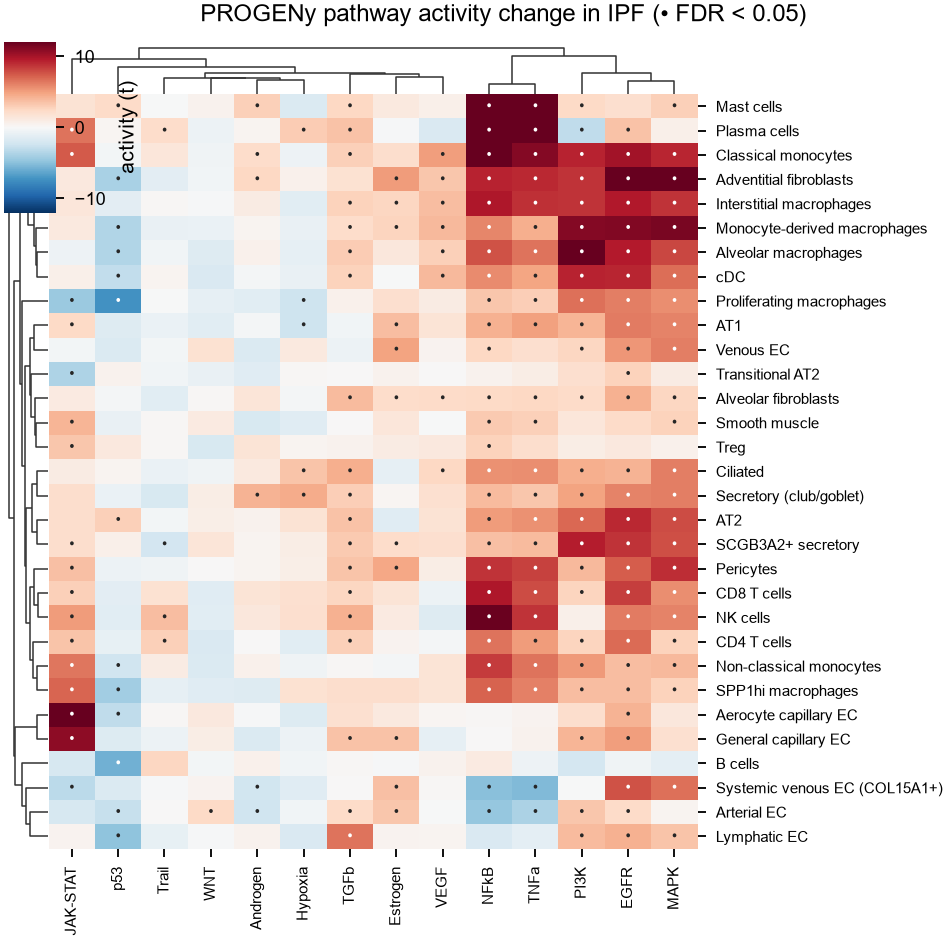

In [3]:
p_sc, p_padj = enrichment.activity_from_stats(stat, progeny)
write_table(p_sc.round(3), TAB / "progeny_scores")
write_table(p_padj, TAB / "progeny_padj")
heatmap(p_sc, p_padj, "PROGENy pathway activity change in IPF (• FDR < 0.05)", "Fig3_progeny_heatmap",
        figsize_mm=(120, 110))

## 3. CollecTRI TF activity

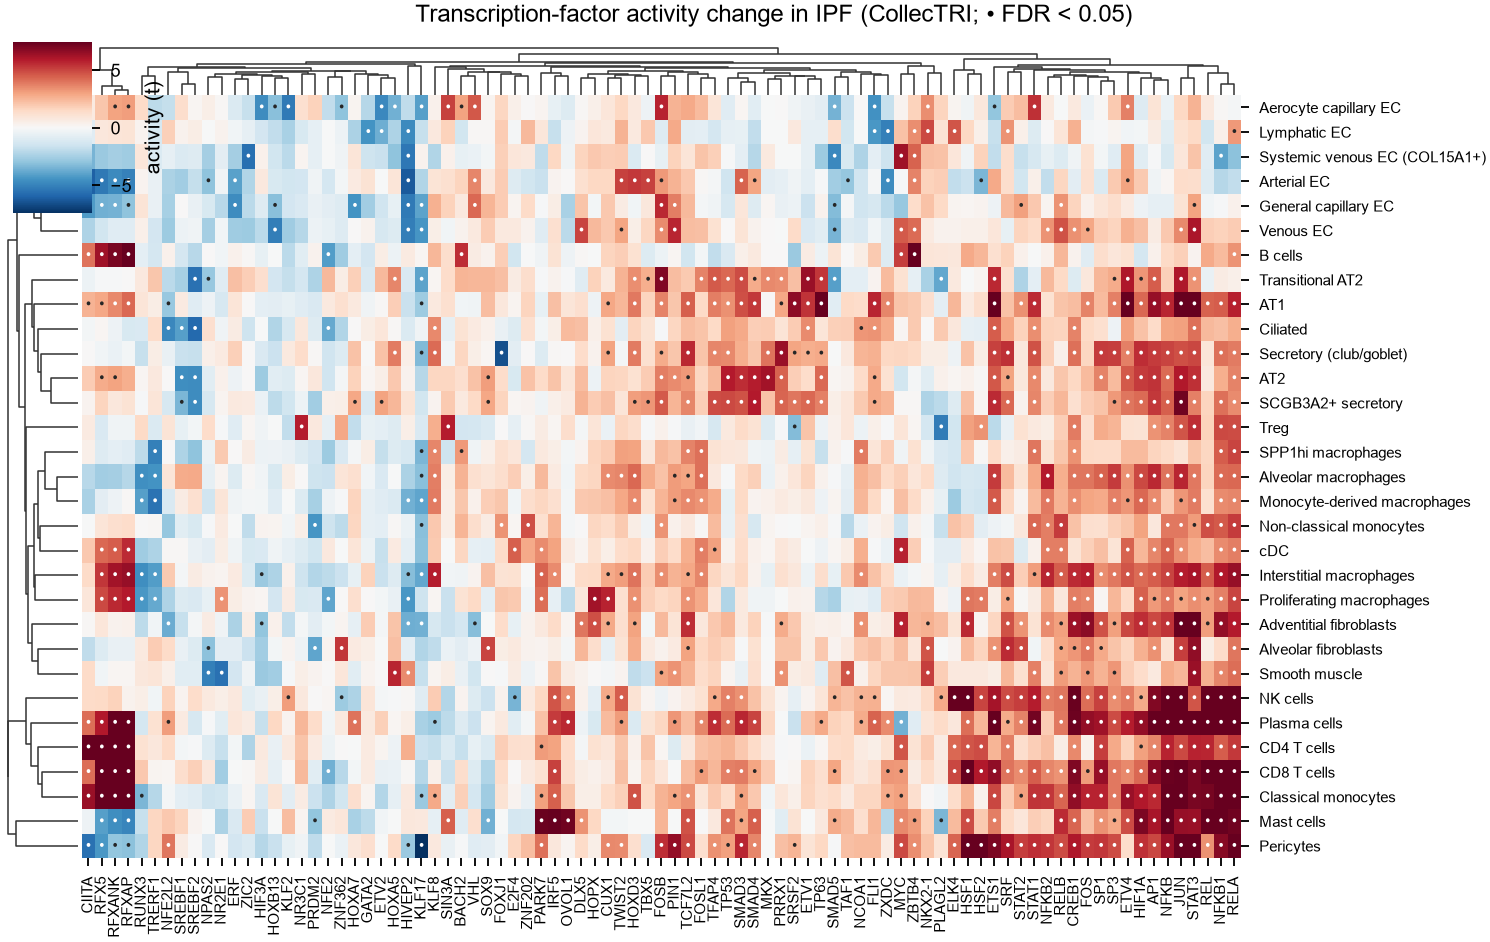

In [4]:
t_sc, t_padj = enrichment.activity_from_stats(stat, collectri)
write_table(t_sc.round(3), TAB / "collectri_scores")
write_table(t_padj, TAB / "collectri_padj")
top = enrichment.top_sources(t_sc, t_padj, n=6)
heatmap(t_sc[top], t_padj[top], "Transcription-factor activity change in IPF (CollecTRI; • FDR < 0.05)",
        "Fig3_collectri_heatmap", figsize_mm=(183, 110))

## 4. MSigDB Hallmarks

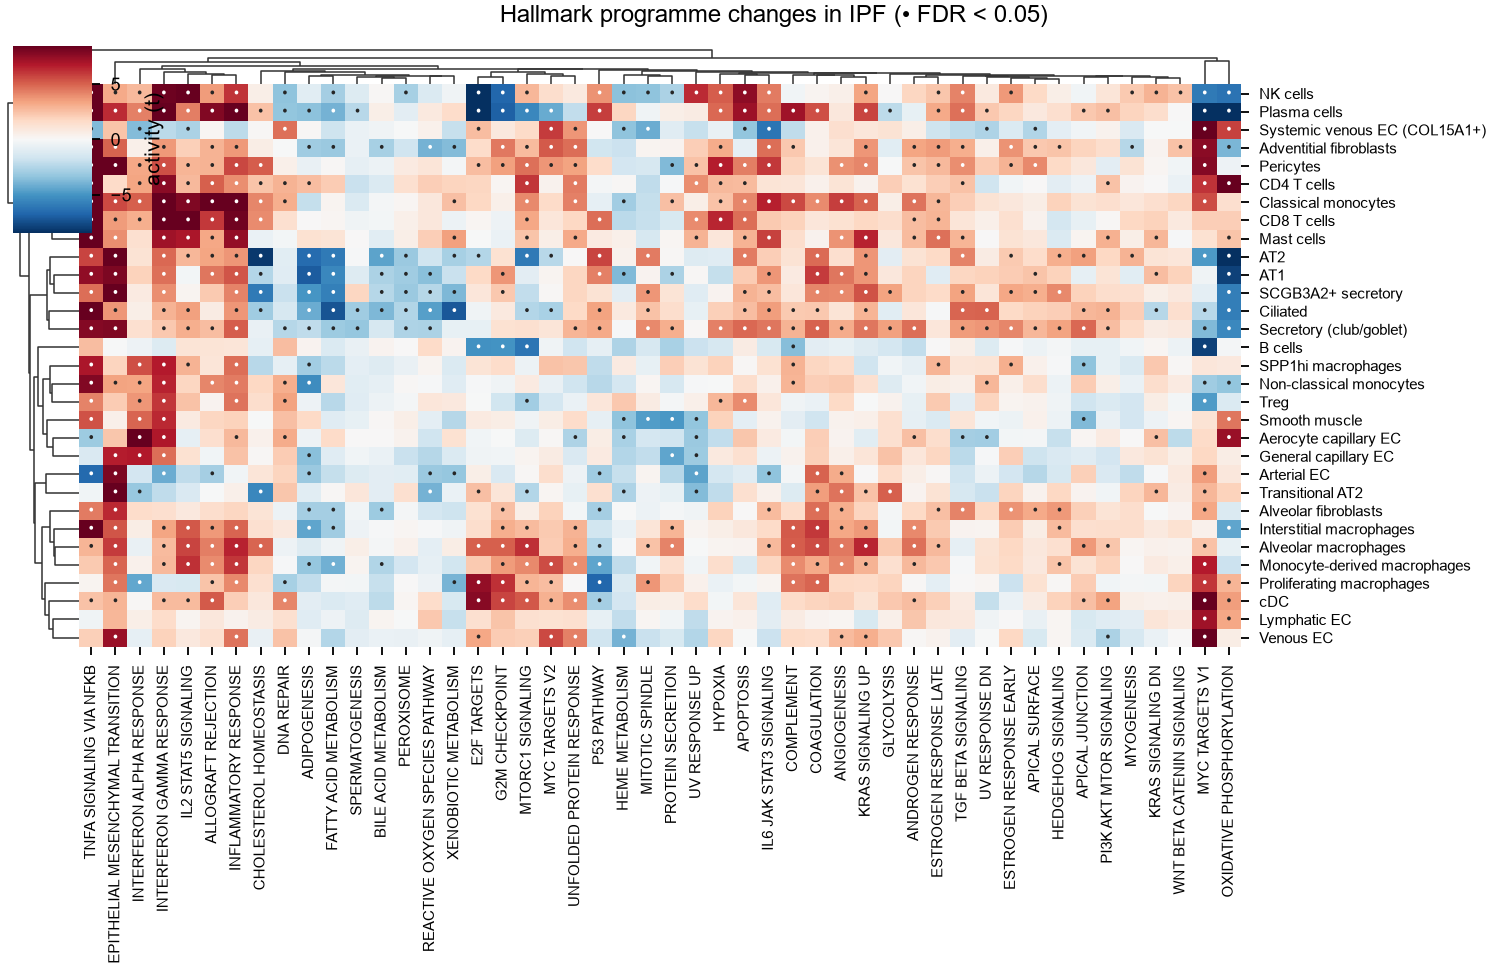

In [5]:
h_sc, h_padj = enrichment.activity_from_stats(stat, hallmark)
write_table(h_sc.round(3), TAB / "hallmark_scores")
write_table(h_padj, TAB / "hallmark_padj")
keep = h_padj.columns[(h_padj < 0.05).sum() >= 2]
heatmap(h_sc[keep], h_padj[keep], "Hallmark programme changes in IPF (• FDR < 0.05)", "S8_hallmark_heatmap",
        figsize_mm=(183, 120))

## 5. Per-cell pathway activity on the atlas
For visualisation, PROGENy activities are also inferred per cell from the
log-normalised expression (scores are relative: they compare a cell with the
average cell).

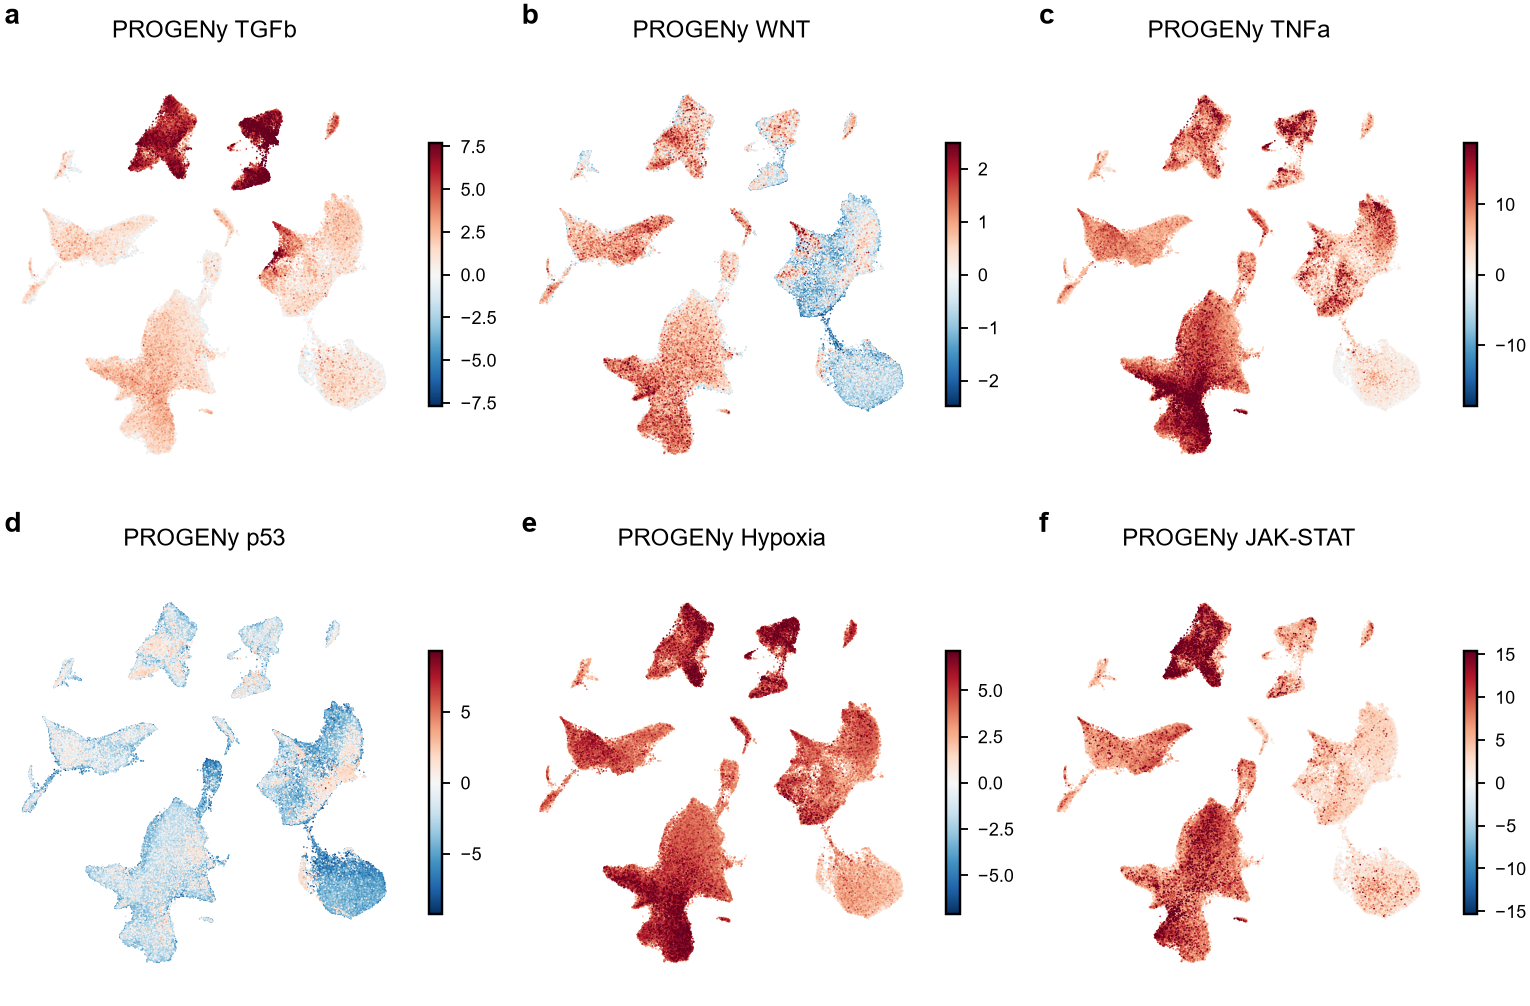

In [6]:
adata = sc.read_h5ad(P.processed / "discovery_annotated.h5ad")
cell_scores = enrichment.ulm_cells(adata, progeny, key="progeny")
paths = ["TGFb", "WNT", "TNFa", "p53", "Hypoxia", "JAK-STAT"]
fig, axes = plt.subplots(2, 3, figsize=figsize(183, 120))
for ax, pw in zip(axes.ravel(), paths):
    v = cell_scores[pw].to_numpy()
    lim = np.nanpercentile(np.abs(v), 99)
    sca = embedding_scatter(ax, adata.obsm["X_umap"], v, cmap="RdBu_r", vmin=-lim, vmax=lim, s=0.3, order="value")
    plt.colorbar(sca, ax=ax, shrink=0.6)
    ax.set_title(f"PROGENy {pw}")
for a, l in zip(axes.ravel(), "abcdef"):
    panel_label(a, l, x=0.0)
fig.tight_layout()
save_figure(fig, "S8_progeny_umap", FIG)
plt.show()

J:\Portfolio_projects\Projects\scRNA\.cache\tmp\ipykernel_4464\2525599201.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  mean_act = cell_scores.groupby(adata.obs["cell_type"].values).mean()


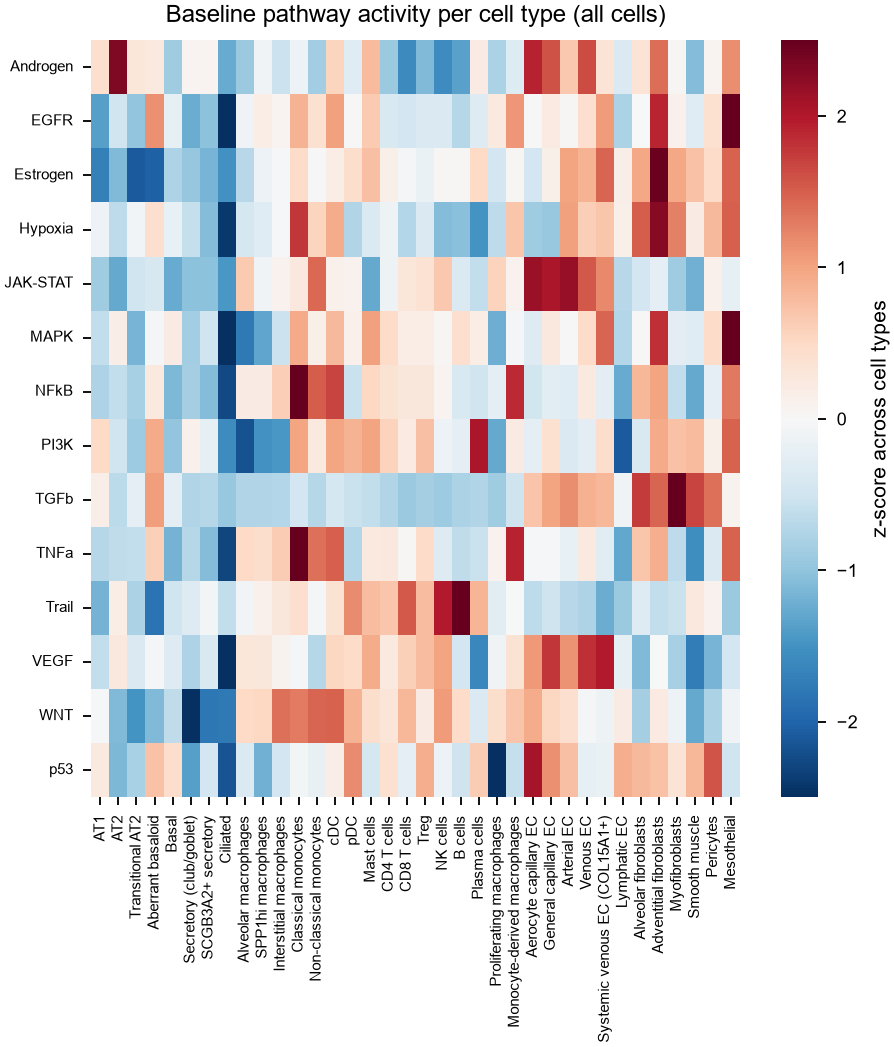

In [7]:
mean_act = cell_scores.groupby(adata.obs["cell_type"].values).mean()
write_table(mean_act.round(3), TAB / "progeny_mean_per_celltype_cells")
fig, ax = plt.subplots(figsize=figsize(120, 115))
sns.heatmap(mean_act.T.apply(lambda r: (r - r.mean()) / r.std(), axis=1), cmap="RdBu_r", center=0, vmin=-2.5,
            vmax=2.5, ax=ax, cbar_kws={"label": "z-score across cell types"}, xticklabels=True)
ax.tick_params(labelsize=5)
ax.set_title("Baseline pathway activity per cell type (all cells)")
save_figure(fig, "S8_progeny_per_celltype", FIG)
plt.show()